# London house prices: data cleaning

Herlyn Dsouza — Task 1. Review the cleaning decisions and saved results below. To regenerate the model runs, use `python -m contributions.herlyn.cleaning_review` from the repository root. This notebook reads saved experiment results and checks the cleaner without retraining.

In [ ]:
from pathlib import Path
import sys
import pandas as pd
ROOT = Path.cwd()
while not (ROOT / 'src/data.py').is_file():
    if ROOT == ROOT.parent:
        raise RuntimeError('Open this notebook inside the team repository')
    ROOT = ROOT.parent
REPORT_DIR = ROOT / 'contributions/herlyn/reports'
sys.path.insert(0, str(ROOT))
from src.data import load_train, time_split
from contributions.herlyn.cleaning import PropertyCleaner, PROPERTY_MAP
train, valid = time_split(load_train(), valid_from_year=2023)
print(f'Train: {len(train):,} rows before 2023; validate: {len(valid):,} rows in 2023')

## Missing data
All learned rules use training rows only. Validation counts are descriptive. Numeric missing values remain NaN in the selected tree-model candidate, with explicit indicators.

In [ ]:
print(pd.read_csv(REPORT_DIR / 'missing_values.csv').to_string(index=False))

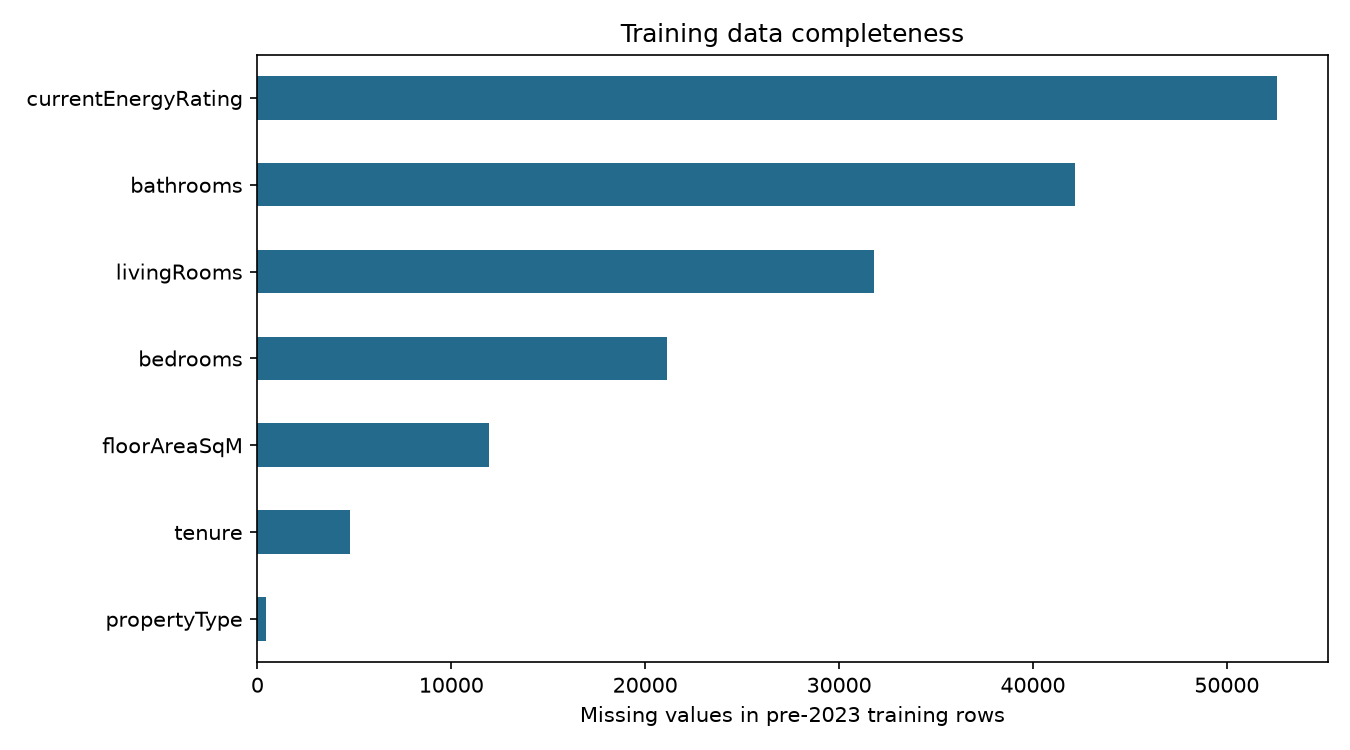

## Property types and tenure
Merge synonymous wording only; retain flat and bungalow distinctions. Rare tenure grouping is available but disabled in the selected candidate.

In [ ]:
print(pd.Series(PROPERTY_MAP, name='standardized_label').to_string())
print('\nTraining tenure counts:')
print(train.tenure.value_counts(dropna=False).to_string())
cleaner = PropertyCleaner(group_rare=False, impute=False).fit(train)
clean_train, clean_valid = cleaner.transform(train), cleaner.transform(valid)
assert clean_train[train.columns].equals(train)
assert clean_valid[valid.columns].equals(valid)
print('\nConfirmed: original columns, targets, order and IDs preserved.')

## Extreme prices and correlated features
Investigate extreme values instead of assuming they are errors. The trimming experiment changes training rows only. Retain correlated predictors for this tree model.

In [ ]:
print((REPORT_DIR / 'data_summary.json').read_text())
print('\nTraining Pearson correlations:')
print(pd.read_csv(REPORT_DIR / 'training_correlations.csv', index_col=0).round(3).to_string())

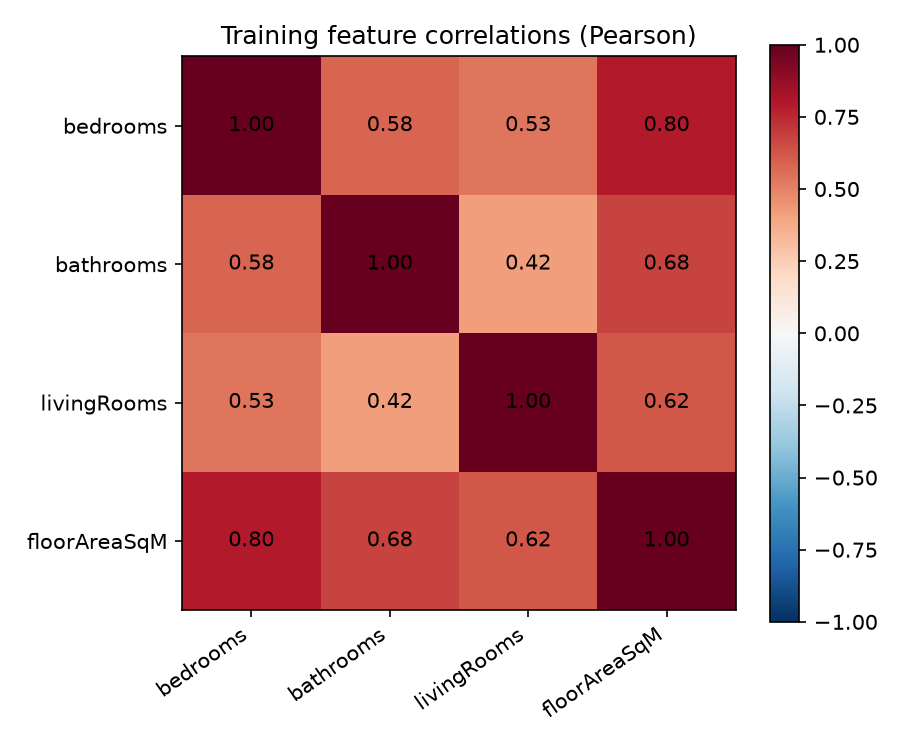

## Model comparison
Same model hyperparameters, seed and validation rows. Previous-sale features are excluded. Imputation and trimming experiments build on the rare-tenure candidate. This is a sequential comparison, not an exhaustive factorial experiment.

In [ ]:
results = pd.read_csv(REPORT_DIR / 'cleaning_comparison.csv')
print(results.to_string(index=False))
base = results.loc[results.experiment.eq('Original gradient boosting'), 'mae_gbp'].iloc[0]
selected = results.loc[results.experiment.eq('Labels + missing flags'), 'mae_gbp'].iloc[0]
print(f'\nObserved improvement: GBP {base-selected:,.2f} ({100*(base-selected)/base:.2f}%)')

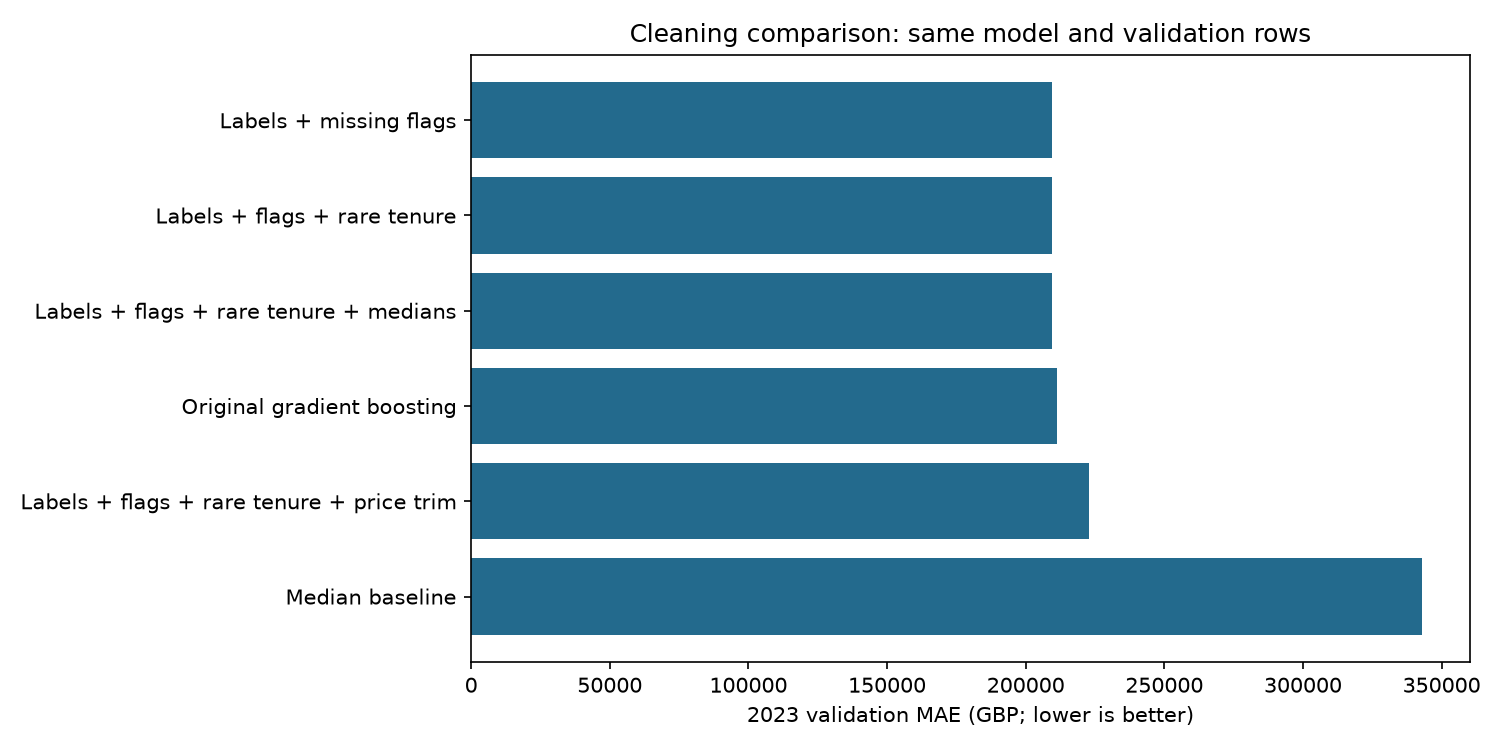

## Recommendation
Use `PropertyCleaner(group_rare=False, impute=False)` and the integration in `contributions.herlyn.cleaning_review.predict_clean`. Keep rare tenure labels, native numeric missing values, extreme prices and correlated features for the selected model. The observed gain is modest and needs additional chronological validation.

The original previous-sale code is unchanged and its two known issues require a separate fix. Full decisions, limitations and report/slide text are in `contributions/herlyn/reports/cleaning_contribution_notes.txt`.